# Spam Classification Project

In [71]:
# Importing required libraries

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

pd.set_option('display.max_colwidth',None)

warnings.filterwarnings('ignore')

In [72]:
# Reading dataset

data=pd.read_csv(r'SMSSpamCollection.txt', sep='\t',header=None,names=['label','message'])
data.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


In [73]:
data.shape

(5572, 2)

In [74]:
data.isnull().sum()

label      0
message    0
dtype: int64

In [75]:
data['label'].value_counts()

label
ham     4825
spam     747
Name: count, dtype: int64

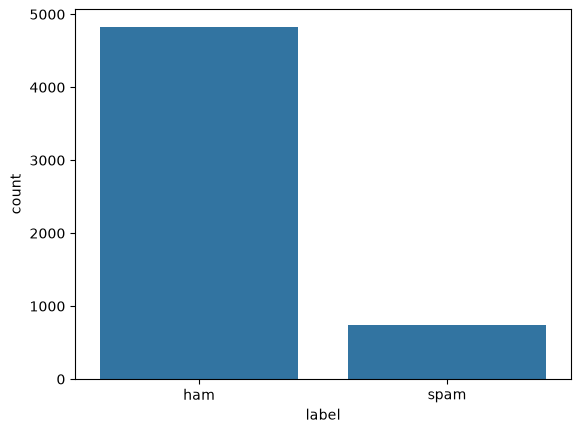

In [76]:
sns.countplot(data=data, x='label');

In [77]:
from sklearn.model_selection import train_test_split

train_data,test_data=train_test_split(data,random_state=42,test_size=0.30,stratify=data['label'])

In [78]:
ham=train_data[train_data['label'] == 'ham']
spam=train_data[train_data['label'] == 'spam']

In [79]:
from sklearn.utils import resample
spam_oversampled=resample(spam,replace=True,n_samples=len(ham),random_state=42)

In [80]:
train_balanced=pd.concat([ham, spam_oversampled])
# Shuffling
train_balanced=train_balanced.sample(frac=1,random_state=42)

In [81]:
train_balanced['label'].value_counts()

label
ham     3377
spam    3377
Name: count, dtype: int64

In [82]:
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

train_balanced['Cleaned_Data']=train_balanced['message'].apply(lambda x : word_tokenize(x))

In [83]:
train_balanced.head()

,label,message,Cleaned_Data
3931,ham,I thk ü gotta go home by urself. Cos i'll b going out shopping 4 my frens present.,"[I, thk, ü, got, ta, go, home, by, urself, ., Cos, i, 'll, b, going, out, shopping, 4, my, frens, present, .]"
2670,spam,we tried to contact you re your response to our offer of a new nokia fone and camcorder hit reply or call 08000930705 for delivery,"[we, tried, to, contact, you, re, your, response, to, our, offer, of, a, new, nokia, fone, and, camcorder, hit, reply, or, call, 08000930705, for, delivery]"
2600,ham,"Gosh that , what a pain. Spose I better come then.","[Gosh, that, ,, what, a, pain, ., Spose, I, better, come, then, .]"
3778,spam,"Mila, age23, blonde, new in UK. I look sex with UK guys. if u like fun with me. Text MTALK to 69866.18 . 30pp/txt 1st 5free. £1.50 increments. Help08718728876","[Mila, ,, age23, ,, blonde, ,, new, in, UK, ., I, look, sex, with, UK, guys, ., if, u, like, fun, with, me, ., Text, MTALK, to, 69866.18, ., 30pp/txt, 1st, 5free, ., £1.50, increments, ., Help08718728876]"
2708,spam,Great NEW Offer - DOUBLE Mins & DOUBLE Txt on best Orange tariffs AND get latest camera phones 4 FREE! Call MobileUpd8 free on 08000839402 NOW! or 2stoptxt T&Cs,"[Great, NEW, Offer, -, DOUBLE, Mins, &, DOUBLE, Txt, on, best, Orange, tariffs, AND, get, latest, camera, phones, 4, FREE, !, Call, MobileUpd8, free, on, 08000839402, NOW, !, or, 2stoptxt, T, &, Cs]"


In [84]:
train_balanced['Cleaned_Data']=train_balanced['Cleaned_Data'].apply(lambda x : [word for word in x if word not in stopwords.words('english')])

In [85]:
train_balanced.head()

,label,message,Cleaned_Data
3931,ham,I thk ü gotta go home by urself. Cos i'll b going out shopping 4 my frens present.,"[I, thk, ü, got, ta, go, home, urself, ., Cos, 'll, b, going, shopping, 4, frens, present, .]"
2670,spam,we tried to contact you re your response to our offer of a new nokia fone and camcorder hit reply or call 08000930705 for delivery,"[tried, contact, response, offer, new, nokia, fone, camcorder, hit, reply, call, 08000930705, delivery]"
2600,ham,"Gosh that , what a pain. Spose I better come then.","[Gosh, ,, pain, ., Spose, I, better, come, .]"
3778,spam,"Mila, age23, blonde, new in UK. I look sex with UK guys. if u like fun with me. Text MTALK to 69866.18 . 30pp/txt 1st 5free. £1.50 increments. Help08718728876","[Mila, ,, age23, ,, blonde, ,, new, UK, ., I, look, sex, UK, guys, ., u, like, fun, ., Text, MTALK, 69866.18, ., 30pp/txt, 1st, 5free, ., £1.50, increments, ., Help08718728876]"
2708,spam,Great NEW Offer - DOUBLE Mins & DOUBLE Txt on best Orange tariffs AND get latest camera phones 4 FREE! Call MobileUpd8 free on 08000839402 NOW! or 2stoptxt T&Cs,"[Great, NEW, Offer, -, DOUBLE, Mins, &, DOUBLE, Txt, best, Orange, tariffs, AND, get, latest, camera, phones, 4, FREE, !, Call, MobileUpd8, free, 08000839402, NOW, !, 2stoptxt, T, &, Cs]"


In [86]:
from nltk.stem import WordNetLemmatizer

train_balanced['Cleaned_Data']=train_balanced['Cleaned_Data'].apply(lambda x :[WordNetLemmatizer().lemmatize(word,pos="v") for word in x]) 

In [87]:
train_balanced.head()

,label,message,Cleaned_Data
3931,ham,I thk ü gotta go home by urself. Cos i'll b going out shopping 4 my frens present.,"[I, thk, ü, get, ta, go, home, urself, ., Cos, 'll, b, go, shop, 4, frens, present, .]"
2670,spam,we tried to contact you re your response to our offer of a new nokia fone and camcorder hit reply or call 08000930705 for delivery,"[try, contact, response, offer, new, nokia, fone, camcorder, hit, reply, call, 08000930705, delivery]"
2600,ham,"Gosh that , what a pain. Spose I better come then.","[Gosh, ,, pain, ., Spose, I, better, come, .]"
3778,spam,"Mila, age23, blonde, new in UK. I look sex with UK guys. if u like fun with me. Text MTALK to 69866.18 . 30pp/txt 1st 5free. £1.50 increments. Help08718728876","[Mila, ,, age23, ,, blonde, ,, new, UK, ., I, look, sex, UK, guy, ., u, like, fun, ., Text, MTALK, 69866.18, ., 30pp/txt, 1st, 5free, ., £1.50, increments, ., Help08718728876]"
2708,spam,Great NEW Offer - DOUBLE Mins & DOUBLE Txt on best Orange tariffs AND get latest camera phones 4 FREE! Call MobileUpd8 free on 08000839402 NOW! or 2stoptxt T&Cs,"[Great, NEW, Offer, -, DOUBLE, Mins, &, DOUBLE, Txt, best, Orange, tariff, AND, get, latest, camera, phone, 4, FREE, !, Call, MobileUpd8, free, 08000839402, NOW, !, 2stoptxt, T, &, Cs]"


In [88]:
train_balanced

,label,message,Cleaned_Data
3931,ham,I thk ü gotta go home by urself. Cos i'll b going out shopping 4 my frens present.,"[I, thk, ü, get, ta, go, home, urself, ., Cos, 'll, b, go, shop, 4, frens, present, .]"
2670,spam,we tried to contact you re your response to our offer of a new nokia fone and camcorder hit reply or call 08000930705 for delivery,"[try, contact, response, offer, new, nokia, fone, camcorder, hit, reply, call, 08000930705, delivery]"
2600,ham,"Gosh that , what a pain. Spose I better come then.","[Gosh, ,, pain, ., Spose, I, better, come, .]"
3778,spam,"Mila, age23, blonde, new in UK. I look sex with UK guys. if u like fun with me. Text MTALK to 69866.18 . 30pp/txt 1st 5free. £1.50 increments. Help08718728876","[Mila, ,, age23, ,, blonde, ,, new, UK, ., I, look, sex, UK, guy, ., u, like, fun, ., Text, MTALK, 69866.18, ., 30pp/txt, 1st, 5free, ., £1.50, increments, ., Help08718728876]"
2708,spam,Great NEW Offer - DOUBLE Mins & DOUBLE Txt on best Orange tariffs AND get latest camera phones 4 FREE! Call MobileUpd8 free on 08000839402 NOW! or 2stoptxt T&Cs,"[Great, NEW, Offer, -, DOUBLE, Mins, &, DOUBLE, Txt, best, Orange, tariff, AND, get, latest, camera, phone, 4, FREE, !, Call, MobileUpd8, free, 08000839402, NOW, !, 2stoptxt, T, &, Cs]"
...,...,...,...
4823,spam,u r a winner U ave been specially selected 2 receive £1000 cash or a 4* holiday (flights inc) speak to a live operator 2 claim 0871277810710p/min (18 ),"[u, r, winner, U, ave, specially, select, 2, receive, £1000, cash, 4, *, holiday, (, flight, inc, ), speak, live, operator, 2, claim, 0871277810710p/min, (, 18, )]"
5190,spam,Our records indicate u maybe entitled to 5000 pounds in compensation for the Accident you had. To claim 4 free reply with CLAIM to this msg. 2 stop txt STOP,"[Our, record, indicate, u, maybe, entitle, 5000, pound, compensation, Accident, ., To, claim, 4, free, reply, CLAIM, msg, ., 2, stop, txt, STOP]"
2378,spam,YES! The only place in town to meet exciting adult singles is now in the UK. Txt CHAT to 86688 now! 150p/Msg.,"[YES, !, The, place, town, meet, excite, adult, single, UK, ., Txt, CHAT, 86688, !, 150p/Msg, .]"
2664,spam,8007 FREE for 1st week! No1 Nokia tone 4 ur mob every week just txt NOKIA to 8007 Get txting and tell ur mates www.getzed.co.uk POBox 36504 W4 5WQ norm 150p/tone 16+,"[8007, FREE, 1st, week, !, No1, Nokia, tone, 4, ur, mob, every, week, txt, NOKIA, 8007, Get, txting, tell, ur, mat, www.getzed.co.uk, POBox, 36504, W4, 5WQ, norm, 150p/tone, 16+]"


In [89]:
import re

train_balanced['Cleaned_Data']=train_balanced['Cleaned_Data'].apply(
    lambda tokens: [clean for t in tokens if (clean := re.sub(r'[^\w\s]', '', t))]
    if isinstance(tokens, list) else tokens)

In [90]:
train_balanced.head()

,label,message,Cleaned_Data
3931,ham,I thk ü gotta go home by urself. Cos i'll b going out shopping 4 my frens present.,"[I, thk, ü, get, ta, go, home, urself, Cos, ll, b, go, shop, 4, frens, present]"
2670,spam,we tried to contact you re your response to our offer of a new nokia fone and camcorder hit reply or call 08000930705 for delivery,"[try, contact, response, offer, new, nokia, fone, camcorder, hit, reply, call, 08000930705, delivery]"
2600,ham,"Gosh that , what a pain. Spose I better come then.","[Gosh, pain, Spose, I, better, come]"
3778,spam,"Mila, age23, blonde, new in UK. I look sex with UK guys. if u like fun with me. Text MTALK to 69866.18 . 30pp/txt 1st 5free. £1.50 increments. Help08718728876","[Mila, age23, blonde, new, UK, I, look, sex, UK, guy, u, like, fun, Text, MTALK, 6986618, 30pptxt, 1st, 5free, 150, increments, Help08718728876]"
2708,spam,Great NEW Offer - DOUBLE Mins & DOUBLE Txt on best Orange tariffs AND get latest camera phones 4 FREE! Call MobileUpd8 free on 08000839402 NOW! or 2stoptxt T&Cs,"[Great, NEW, Offer, DOUBLE, Mins, DOUBLE, Txt, best, Orange, tariff, AND, get, latest, camera, phone, 4, FREE, Call, MobileUpd8, free, 08000839402, NOW, 2stoptxt, T, Cs]"


In [91]:
stop_words=set(stopwords.words('english'))
train_balanced['Cleaned_Data']=train_balanced['Cleaned_Data'].apply(
    lambda tokens: ' '.join(t.lower() for t in tokens if t.lower() not in stop_words and len(t) > 1))
train_balanced.head()

,label,message,Cleaned_Data
3931,ham,I thk ü gotta go home by urself. Cos i'll b going out shopping 4 my frens present.,thk get ta go home urself cos go shop frens present
2670,spam,we tried to contact you re your response to our offer of a new nokia fone and camcorder hit reply or call 08000930705 for delivery,try contact response offer new nokia fone camcorder hit reply call 08000930705 delivery
2600,ham,"Gosh that , what a pain. Spose I better come then.",gosh pain spose better come
3778,spam,"Mila, age23, blonde, new in UK. I look sex with UK guys. if u like fun with me. Text MTALK to 69866.18 . 30pp/txt 1st 5free. £1.50 increments. Help08718728876",mila age23 blonde new uk look sex uk guy like fun text mtalk 6986618 30pptxt 1st 5free 150 increments help08718728876
2708,spam,Great NEW Offer - DOUBLE Mins & DOUBLE Txt on best Orange tariffs AND get latest camera phones 4 FREE! Call MobileUpd8 free on 08000839402 NOW! or 2stoptxt T&Cs,great new offer double mins double txt best orange tariff get latest camera phone free call mobileupd8 free 08000839402 2stoptxt cs


In [92]:
train_balanced['label']=train_balanced['label'].map({'ham':0 ,'spam':1})

In [93]:
train_balanced.head()

,label,message,Cleaned_Data
3931,0,I thk ü gotta go home by urself. Cos i'll b going out shopping 4 my frens present.,thk get ta go home urself cos go shop frens present
2670,1,we tried to contact you re your response to our offer of a new nokia fone and camcorder hit reply or call 08000930705 for delivery,try contact response offer new nokia fone camcorder hit reply call 08000930705 delivery
2600,0,"Gosh that , what a pain. Spose I better come then.",gosh pain spose better come
3778,1,"Mila, age23, blonde, new in UK. I look sex with UK guys. if u like fun with me. Text MTALK to 69866.18 . 30pp/txt 1st 5free. £1.50 increments. Help08718728876",mila age23 blonde new uk look sex uk guy like fun text mtalk 6986618 30pptxt 1st 5free 150 increments help08718728876
2708,1,Great NEW Offer - DOUBLE Mins & DOUBLE Txt on best Orange tariffs AND get latest camera phones 4 FREE! Call MobileUpd8 free on 08000839402 NOW! or 2stoptxt T&Cs,great new offer double mins double txt best orange tariff get latest camera phone free call mobileupd8 free 08000839402 2stoptxt cs


In [128]:
train_balanced.to_csv('train_processed_data.csv', index=False)

In [185]:
X_train=train_balanced['Cleaned_Data']
y_train=train_balanced[['label']]

In [186]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf=TfidfVectorizer(ngram_range=(1,1),min_df=8)
X_train=tfidf.fit_transform(X_train)
X_train=pd.DataFrame(X_train.toarray(),columns=tfidf.get_feature_names_out())
X_train.head()

,0121,01223585334,020603,0207,02073162414,020903,021,050703,0578,07046744435,...,yer,yes,yesterday,yet,yo,yr,yrs,yup,zed,zoe
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [187]:
X_test=tfidf.transform(test_data['message'])
y_test=test_data['label'].map({'ham': 0, 'spam': 1})

In [188]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix,accuracy_score

model=MultinomialNB()
model.fit(X_train, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[3377.,3377.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.69,-0.69]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 1827)","[[ 0. , 0. , 0. ,...,16.98, 0. , 0.49], [ 3.19, 3.95, 2.96,..., 0. , 6.94, 2.26]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 1827)","[[-9.09,-9.09,-9.09,...,-6.2 ,-9.09,-8.69], [-8.11,-7.94,-8.17,...,-9.54,-7.47,-8.36]]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1827,)","['0121','01223585334','020603',...,'yup','zed','zoe']"


In [189]:

print('------------------Accuracy Report on Training Data---------------\n\n')
y_pred=model.predict(X_train)
print(confusion_matrix(y_train, y_pred))
print(classification_report(y_train, y_pred, target_names=['ham', 'spam']))
print(accuracy_score(y_train,y_pred))

------------------Accuracy Report on Training Data---------------


[[3306   71]
 [  93 3284]]
              precision    recall  f1-score   support

         ham       0.97      0.98      0.98      3377
        spam       0.98      0.97      0.98      3377

    accuracy                           0.98      6754
   macro avg       0.98      0.98      0.98      6754
weighted avg       0.98      0.98      0.98      6754

0.9757180929819367


In [190]:

print('------------------Accuracy Report on Testing Data---------------\n\n')
y_pred=model.predict(X_test)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=['ham', 'spam']))
print(accuracy_score(y_test,y_pred))

------------------Accuracy Report on Testing Data---------------


[[1403   45]
 [  15  209]]
              precision    recall  f1-score   support

         ham       0.99      0.97      0.98      1448
        spam       0.82      0.93      0.87       224

    accuracy                           0.96      1672
   macro avg       0.91      0.95      0.93      1672
weighted avg       0.97      0.96      0.97      1672

0.9641148325358851


In [207]:
# Testing on some messages

msg=pd.Series([
    # --- Clear Spam ---
    "CONGRATULATIONS! You have won a £1000 gift card. Call 09061701461 now to claim your prize. Valid for 24 hrs only!",
    "URGENT! Your bank account has been suspended. Reply with your 6-digit OTP and PIN to verify your identity immediately.",
    "FREE entry into our £250 weekly draw! Just txt WIN to 80085 now. T&Cs apply, 150p/msg.",
    "You have been selected for a pre-approved cash loan of 5000 pounds with 0% interest. Call 08001234567 today!",
    "Get a brand new iPhone for FREE! Click www.claim-reward-now.com before midnight. Txt STOP to opt out.",

    # --- Clear Ham ---
    "Hey, are u coming to class tomorrow? The morning lecture got moved to 11.",
    "Can u pick up some milk and bread on ur way back home? Thanks!",
    "Sorry I missed ur call, was stuck in traffic. Will call u back in 10 mins.",
    "Happy birthday! Hope u have an amazing day. Let's catch up this weekend.",
    "I reached home safely. Text me once u get back.",

    # --- Tricky Edge Cases (Test for False Positives & False Negatives) ---
    "Your verification code is 482910. Do not share this OTP with anyone.",  # Legitimate OTP (Ham)
    "Hey, my cousin is giving away free tickets to tonight's match, do u want one?",  # Has "free" + "u" (Ham)
    "Hi, I saw your resume and wanted to know if you are interested in a part-time remote role paying 2000 daily."  # Polite/no-caps scam (Spam)
])

pred=model.predict(tfidf.transform(msg))
results_df=pd.DataFrame({'Message': msg,'Prediction': ['Spam' if p == 1 else 'Ham' for p in pred]})
results_df

,Message,Prediction
0,CONGRATULATIONS! You have won a £1000 gift card. Call 09061701461 now to claim your prize. Valid for 24 hrs only!,Spam
1,URGENT! Your bank account has been suspended. Reply with your 6-digit OTP and PIN to verify your identity immediately.,Spam
2,"FREE entry into our £250 weekly draw! Just txt WIN to 80085 now. T&Cs apply, 150p/msg.",Spam
3,You have been selected for a pre-approved cash loan of 5000 pounds with 0% interest. Call 08001234567 today!,Spam
4,Get a brand new iPhone for FREE! Click www.claim-reward-now.com before midnight. Txt STOP to opt out.,Spam
5,"Hey, are u coming to class tomorrow? The morning lecture got moved to 11.",Ham
6,Can u pick up some milk and bread on ur way back home? Thanks!,Ham
7,"Sorry I missed ur call, was stuck in traffic. Will call u back in 10 mins.",Spam
8,Happy birthday! Hope u have an amazing day. Let's catch up this weekend.,Ham
9,I reached home safely. Text me once u get back.,Ham
